# B · Compare host feature profiles by pathogen group

This notebook compares the **resolved question sets** for every configured host and pathogen group. A feature is counted for a host and pathogen group only when it has a positive value for at least `MIN_PATHOGENS_PER_HOST` distinct pathogens in that host/group. Each matrix cell is the Jaccard similarity: shared applicable features divided by the union of applicable features.

The interactive section compares two hosts and a pathogen group using only their shared feature questions. Each pathogen is one row and each shared feature is one input column. It uses IMSTE when at least three scored pathogen rows are available, with a PCA fallback for two rows. Circle, square, and diamond markers distinguish Both, First, and Second host associations.

In [13]:
import sys
from pathlib import Path

from IPython.display import display

# Find the version4 project root when launched from either the repo or notebooks directory.
candidates = [Path.cwd().resolve(), Path.cwd().resolve() / "notebooks"]
PROJECT_ROOT = next(
    (parent for candidate in candidates for parent in (candidate, *candidate.parents)
     if (parent / "configs/host_choices.yaml").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the version4 project root (configs/host_choices.yaml).")

PACKAGE_ROOT = PROJECT_ROOT
NOTEBOOK_SRC = PROJECT_ROOT / "notebooks/src"
for import_path in (PACKAGE_ROOT, NOTEBOOK_SRC):
    if str(import_path) not in sys.path:
        sys.path.insert(0, str(import_path))

from host_feature_comparison import (
    build_jaccard_analysis,
    create_interactive_host_comparison,
    plot_jaccard_matrices,
)

# Set to a collection such as {"pathogen_host_pair"} to restrict the comparison.
SCOPE_FILTER = None
# Minimum distinct pathogens with a positive feature value for a host/group.
MIN_PATHOGENS_PER_HOST = 2
analysis = build_jaccard_analysis(
    PROJECT_ROOT,
    scope_filter=SCOPE_FILTER,
    min_pathogens_per_host=MIN_PATHOGENS_PER_HOST,
)

## 1 · Resolved profile sizes

Host aliases that share an NCBI taxon ID are collapsed to one profile. Feature identities include the feature ID, question version, and scope.

In [14]:
display(analysis["profile_counts"].sort_values(["pathogen_group", "host"]).reset_index(drop=True))

,pathogen_group,host,host_id,host_group,feature_count
0,bacteria,Atlantic cod,ncbi:8049,fish,17
1,bacteria,Atlantic salmon,ncbi:8030,fish,17
2,bacteria,Cattle,ncbi:9913,livestock,29
3,bacteria,Chicken,ncbi:9031,livestock,29
4,bacteria,Human,ncbi:9606,human,122
5,bacteria,Maize,ncbi:4577,crop,31
6,bacteria,Pig,ncbi:9823,livestock,29
7,bacteria,Rice,ncbi:4530,crop,31
8,bacteria,Sheep,ncbi:9940,livestock,29
9,bacteria,Soybean,ncbi:3847,crop,31


## 2 · Jaccard matrices

Rows and columns use the same configured host order. Empty profiles produce undefined (`NaN`) comparisons; the diagonal is 1 for non-empty profiles.

In [15]:
for pathogen_group, matrix in analysis["matrices"].items():
    print(f"{pathogen_group} · host feature-set Jaccard matrix")
    display(matrix)

bacteria · host feature-set Jaccard matrix


,Human,Cattle,Sheep,Chicken,Pig,Maize,Rice,Wheat,Soybean,Atlantic cod,Atlantic salmon
Human,1.000000,0.237705,0.237705,0.237705,0.237705,0.125000,0.125000,0.125000,0.125000,0.139344,0.139344
Cattle,0.237705,1.000000,1.000000,1.000000,1.000000,0.395349,0.395349,0.395349,0.395349,0.586207,0.586207
Sheep,0.237705,1.000000,1.000000,1.000000,1.000000,0.395349,0.395349,0.395349,0.395349,0.586207,0.586207
Chicken,0.237705,1.000000,1.000000,1.000000,1.000000,0.395349,0.395349,0.395349,0.395349,0.586207,0.586207
Pig,0.237705,1.000000,1.000000,1.000000,1.000000,0.395349,0.395349,0.395349,0.395349,0.586207,0.586207
Maize,0.125000,0.395349,0.395349,0.395349,0.395349,1.000000,1.000000,1.000000,1.000000,0.548387,0.548387
Rice,0.125000,0.395349,0.395349,0.395349,0.395349,1.000000,1.000000,1.000000,1.000000,0.548387,0.548387
Wheat,0.125000,0.395349,0.395349,0.395349,0.395349,1.000000,1.000000,1.000000,1.000000,0.548387,0.548387
Soybean,0.125000,0.395349,0.395349,0.395349,0.395349,1.000000,1.000000,1.000000,1.000000,0.548387,0.548387
Atlantic cod,0.139344,0.586207,0.586207,0.586207,0.586207,0.548387,0.548387,0.548387,0.548387,1.000000,1.000000


fungi · host feature-set Jaccard matrix


,Human,Cattle,Sheep,Chicken,Pig,Maize,Rice,Wheat,Soybean,Atlantic cod,Atlantic salmon
Human,1.000000,0.259259,0.259259,0.259259,0.259259,0.131148,0.131148,0.131148,0.131148,0.148148,0.148148
Cattle,0.259259,1.000000,1.000000,1.000000,1.000000,0.380952,0.380952,0.380952,0.380952,0.571429,0.571429
Sheep,0.259259,1.000000,1.000000,1.000000,1.000000,0.380952,0.380952,0.380952,0.380952,0.571429,0.571429
Chicken,0.259259,1.000000,1.000000,1.000000,1.000000,0.380952,0.380952,0.380952,0.380952,0.571429,0.571429
Pig,0.259259,1.000000,1.000000,1.000000,1.000000,0.380952,0.380952,0.380952,0.380952,0.571429,0.571429
Maize,0.131148,0.380952,0.380952,0.380952,0.380952,1.000000,1.000000,1.000000,1.000000,0.533333,0.533333
Rice,0.131148,0.380952,0.380952,0.380952,0.380952,1.000000,1.000000,1.000000,1.000000,0.533333,0.533333
Wheat,0.131148,0.380952,0.380952,0.380952,0.380952,1.000000,1.000000,1.000000,1.000000,0.533333,0.533333
Soybean,0.131148,0.380952,0.380952,0.380952,0.380952,1.000000,1.000000,1.000000,1.000000,0.533333,0.533333
Atlantic cod,0.148148,0.571429,0.571429,0.571429,0.571429,0.533333,0.533333,0.533333,0.533333,1.000000,1.000000


viruses · host feature-set Jaccard matrix


,Human,Cattle,Sheep,Chicken,Pig,Maize,Rice,Wheat,Soybean,Atlantic cod,Atlantic salmon
Human,1.000000,0.298851,0.298851,0.298851,0.298851,0.127451,0.114035,0.127451,0.127451,0.149425,0.149425
Cattle,0.298851,1.000000,1.000000,1.000000,1.000000,0.317073,0.245283,0.317073,0.317073,0.500000,0.500000
Sheep,0.298851,1.000000,1.000000,1.000000,1.000000,0.317073,0.245283,0.317073,0.317073,0.500000,0.500000
Chicken,0.298851,1.000000,1.000000,1.000000,1.000000,0.317073,0.245283,0.317073,0.317073,0.500000,0.500000
Pig,0.298851,1.000000,1.000000,1.000000,1.000000,0.317073,0.245283,0.317073,0.317073,0.500000,0.500000
Maize,0.127451,0.317073,0.317073,0.317073,0.317073,1.000000,0.700000,1.000000,1.000000,0.464286,0.464286
Rice,0.114035,0.245283,0.245283,0.245283,0.245283,0.700000,1.000000,0.700000,0.700000,0.325000,0.325000
Wheat,0.127451,0.317073,0.317073,0.317073,0.317073,1.000000,0.700000,1.000000,1.000000,0.464286,0.464286
Soybean,0.127451,0.317073,0.317073,0.317073,0.317073,1.000000,0.700000,1.000000,1.000000,0.464286,0.464286
Atlantic cod,0.149425,0.500000,0.500000,0.500000,0.500000,0.464286,0.325000,0.464286,0.464286,1.000000,1.000000


parasites · host feature-set Jaccard matrix


,Human,Cattle,Sheep,Chicken,Pig,Maize,Rice,Wheat,Soybean,Atlantic cod,Atlantic salmon
Human,1.000000,0.333333,0.333333,0.333333,0.333333,0.157895,0.157895,0.157895,0.157895,0.185185,0.185185
Cattle,0.333333,1.000000,1.000000,1.000000,1.000000,0.365854,0.365854,0.365854,0.365854,0.555556,0.555556
Sheep,0.333333,1.000000,1.000000,1.000000,1.000000,0.365854,0.365854,0.365854,0.365854,0.555556,0.555556
Chicken,0.333333,1.000000,1.000000,1.000000,1.000000,0.365854,0.365854,0.365854,0.365854,0.555556,0.555556
Pig,0.333333,1.000000,1.000000,1.000000,1.000000,0.365854,0.365854,0.365854,0.365854,0.555556,0.555556
Maize,0.157895,0.365854,0.365854,0.365854,0.365854,1.000000,1.000000,1.000000,1.000000,0.517241,0.517241
Rice,0.157895,0.365854,0.365854,0.365854,0.365854,1.000000,1.000000,1.000000,1.000000,0.517241,0.517241
Wheat,0.157895,0.365854,0.365854,0.365854,0.365854,1.000000,1.000000,1.000000,1.000000,0.517241,0.517241
Soybean,0.157895,0.365854,0.365854,0.365854,0.365854,1.000000,1.000000,1.000000,1.000000,0.517241,0.517241
Atlantic cod,0.185185,0.555556,0.555556,0.555556,0.555556,0.517241,0.517241,0.517241,0.517241,1.000000,1.000000


oomycetes · host feature-set Jaccard matrix


,Human,Cattle,Sheep,Chicken,Pig,Maize,Rice,Wheat,Soybean,Atlantic cod,Atlantic salmon
Human,1.000000,0.316456,0.316456,0.316456,0.316456,0.138298,0.138298,0.138298,0.138298,0.164557,0.164557
Cattle,0.316456,1.000000,1.000000,1.000000,1.000000,0.325000,0.325000,0.325000,0.325000,0.520000,0.520000
Sheep,0.316456,1.000000,1.000000,1.000000,1.000000,0.325000,0.325000,0.325000,0.325000,0.520000,0.520000
Chicken,0.316456,1.000000,1.000000,1.000000,1.000000,0.325000,0.325000,0.325000,0.325000,0.520000,0.520000
Pig,0.316456,1.000000,1.000000,1.000000,1.000000,0.325000,0.325000,0.325000,0.325000,0.520000,0.520000
Maize,0.138298,0.325000,0.325000,0.325000,0.325000,1.000000,1.000000,1.000000,1.000000,0.464286,0.464286
Rice,0.138298,0.325000,0.325000,0.325000,0.325000,1.000000,1.000000,1.000000,1.000000,0.464286,0.464286
Wheat,0.138298,0.325000,0.325000,0.325000,0.325000,1.000000,1.000000,1.000000,1.000000,0.464286,0.464286
Soybean,0.138298,0.325000,0.325000,0.325000,0.325000,1.000000,1.000000,1.000000,1.000000,0.464286,0.464286
Atlantic cod,0.164557,0.520000,0.520000,0.520000,0.520000,0.464286,0.464286,0.464286,0.464286,1.000000,1.000000


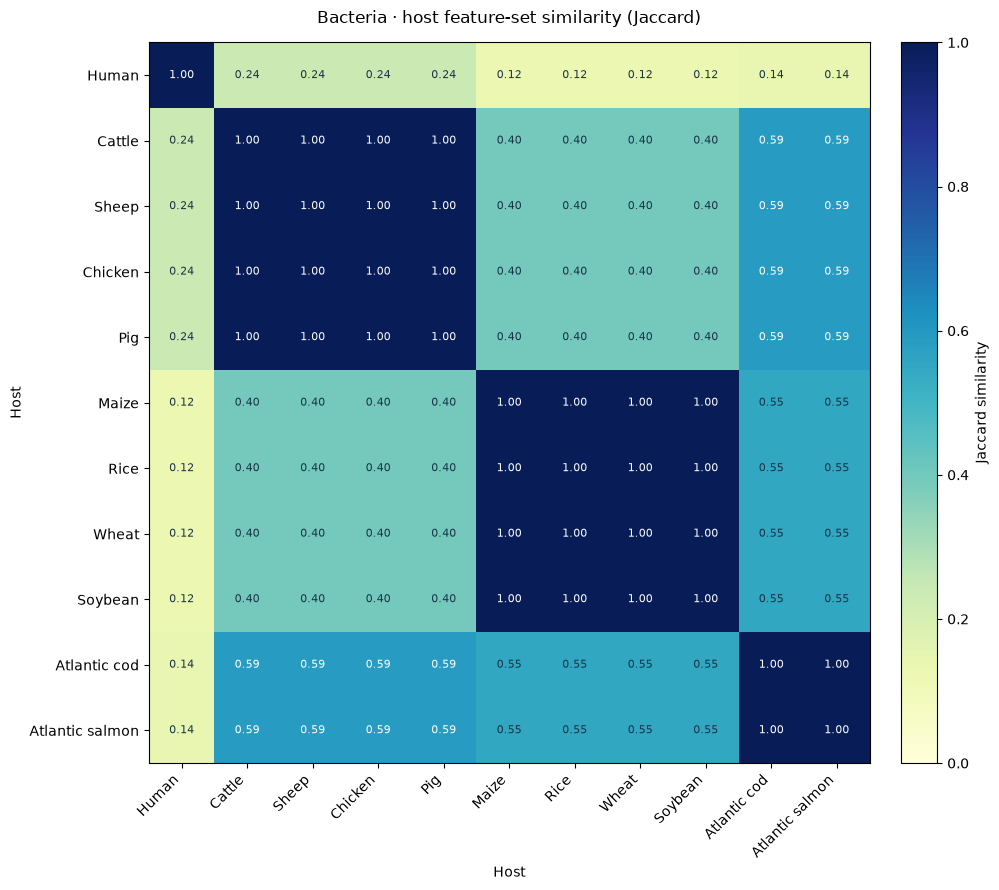

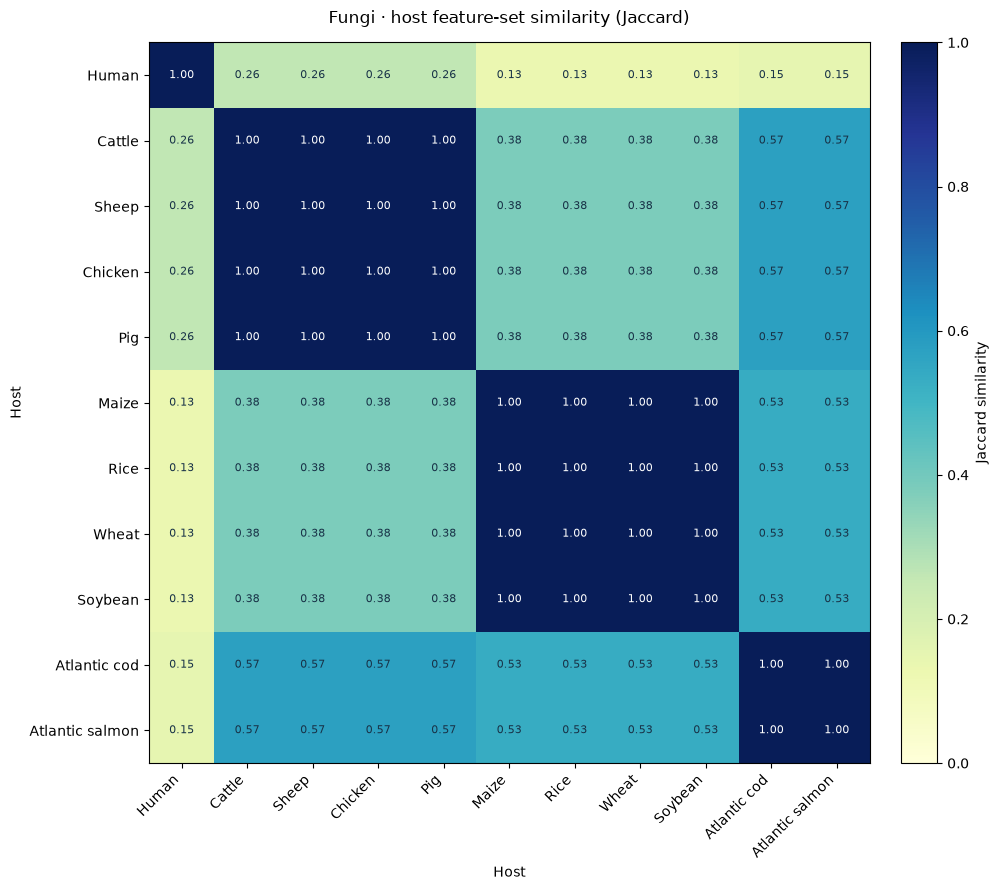

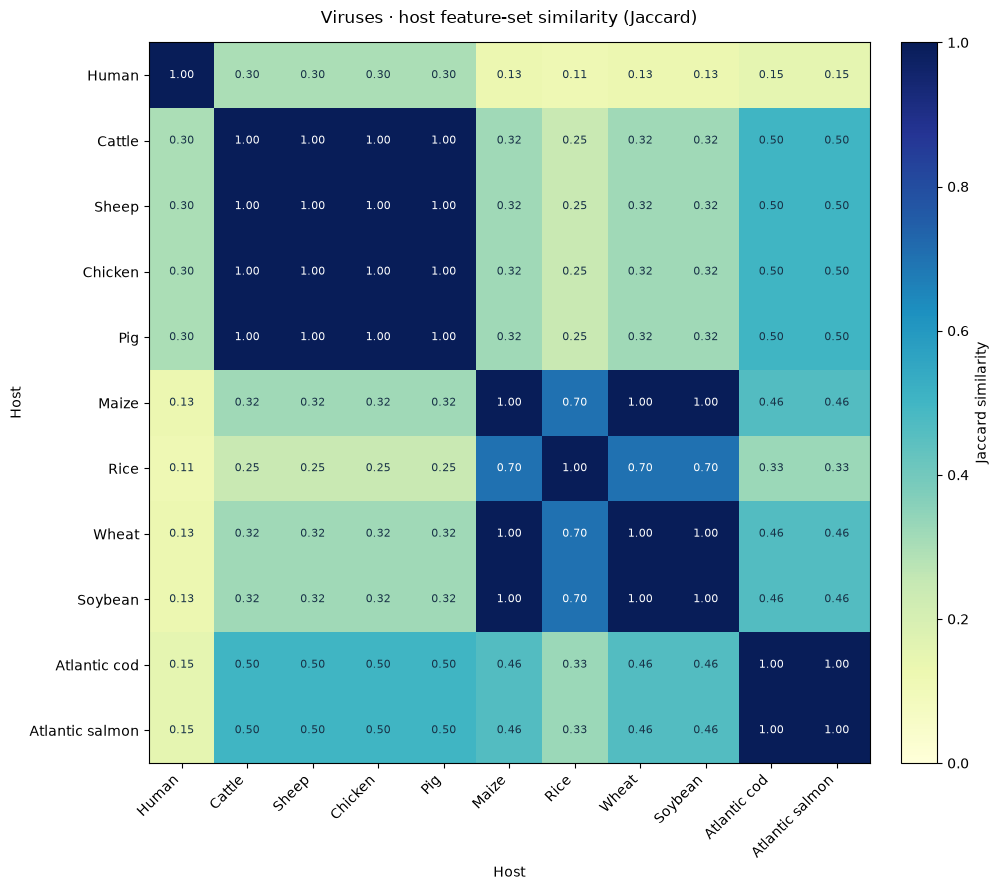

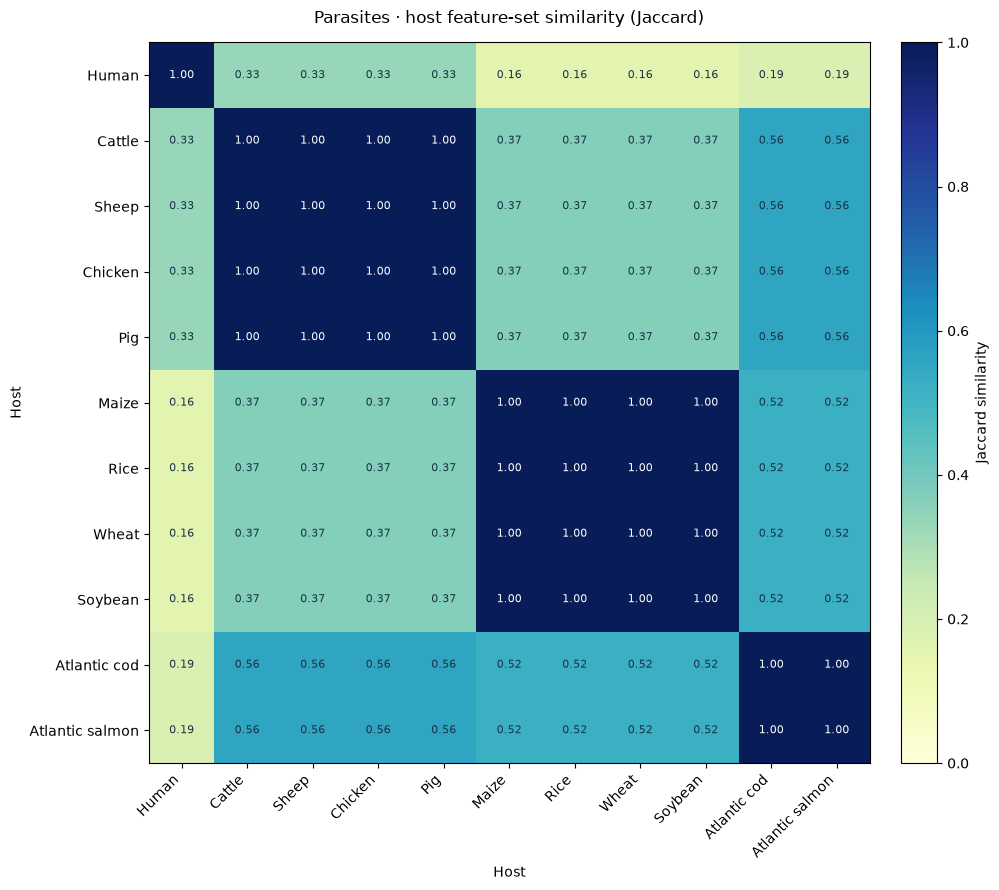

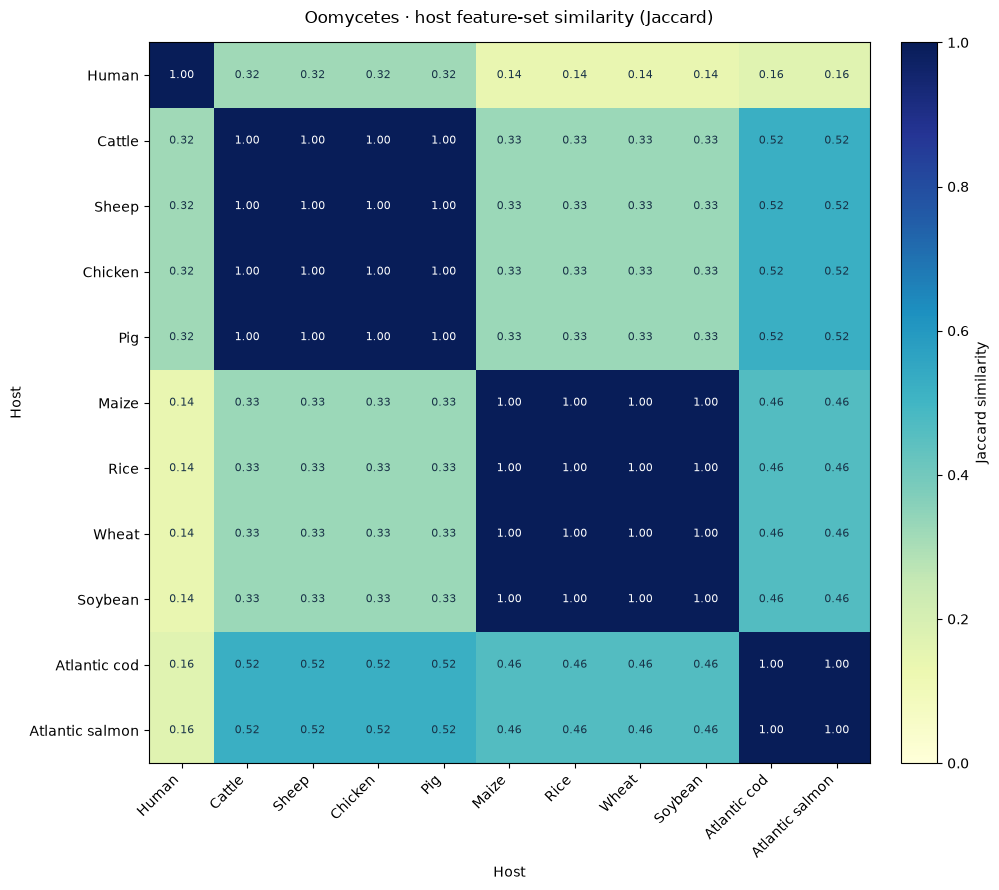

In [16]:
plot_jaccard_matrices(analysis)

## 3 · Pairwise overlap details

The table exposes the shared-feature count and union size behind each matrix score.

In [17]:
display(
    analysis["pairwise_comparisons"]
    .sort_values(["pathogen_group", "jaccard", "host_a", "host_b"], ascending=[True, False, True, True])
    .reset_index(drop=True)
)

,pathogen_group,host_a,host_b,features_a,features_b,intersection,union,jaccard,shared_feature_ids
0,bacteria,Atlantic cod,Atlantic salmon,17,17,17,17,1.000000,abstract_reports_disease; bacterial_antimicrob...
1,bacteria,Cattle,Chicken,29,29,29,29,1.000000,abstract_reports_disease; animal_asymptomatic_...
2,bacteria,Cattle,Pig,29,29,29,29,1.000000,abstract_reports_disease; animal_asymptomatic_...
3,bacteria,Cattle,Sheep,29,29,29,29,1.000000,abstract_reports_disease; animal_asymptomatic_...
4,bacteria,Chicken,Pig,29,29,29,29,1.000000,abstract_reports_disease; animal_asymptomatic_...
...,...,...,...,...,...,...,...,...,...
270,viruses,Human,Atlantic salmon,87,13,13,87,0.149425,abstract_reports_disease; pair_coinfection; pa...
271,viruses,Human,Maize,87,28,13,102,0.127451,abstract_reports_disease; pair_coinfection; pa...
272,viruses,Human,Soybean,87,28,13,102,0.127451,abstract_reports_disease; pair_coinfection; pa...
273,viruses,Human,Wheat,87,28,13,102,0.127451,abstract_reports_disease; pair_coinfection; pa...


## 4 · Compare two hosts in one shared-feature space

The map uses the intersection of the selected hosts’ resolved feature identities. Each dot is a pathogen; each shared feature is an input column. A pathogen is included when either host has a confirmed association and scored values for the shared features. Missing feature values are never replaced by zero. The map reports how many confirmed pathogens have the feature scores needed to plot. Hover points to inspect each host’s association status and supporting PMID counts.

In [ ]:
display(create_interactive_host_comparison(PROJECT_ROOT, scope_filter=SCOPE_FILTER))